# Micrograd Interactive Demo
This notebook demonstrates the scalar autograd engine, computational graph rendering, and neural network training.

In [1]:
# 1. Imports
import sys, os
sys.path.insert(0, os.path.abspath(".." if os.path.exists("../micrograd") else "."))

from micrograd import Value, MLP, draw_dot

## 2. Single Neuron Forward & Backward Pass
Run the cell below to compute backpropagation and visualize the computational graph inline.

Output: 0.7071 | grad: 1.0000
w1.grad: 1.0000 | x1.grad: -1.5000


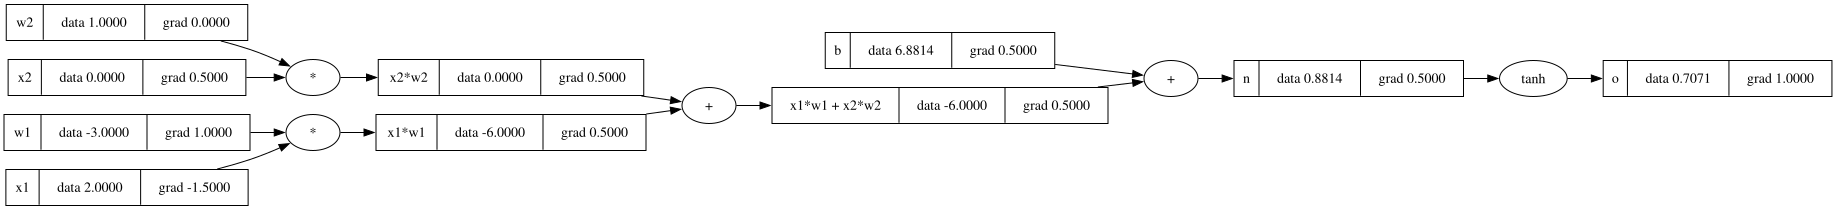

In [2]:
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label="x2")
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")
b = Value(6.8813735870195432, label="b")

x1w1 = x1 * w1; x1w1.label = "x1*w1"
x2w2 = x2 * w2; x2w2.label = "x2*w2"
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = "x1*w1 + x2*w2"
n = x1w1x2w2 + b; n.label = "n"
o = n.tanh(); o.label = "o"

o.backward()

print(f"Output: {o.data:.4f} | grad: {o.grad:.4f}")
print(f"w1.grad: {w1.grad:.4f} | x1.grad: {x1.grad:.4f}")

# Returning the Digraph displays it inline in the notebook:
draw_dot(o)

## 3. Train a 2-Layer MLP
Train a small 2-layer MLP on a single target and visualize the loss graph.

Step  0 | Loss: 0.012621 | Pred: +0.8877
Step  5 | Loss: 0.011128 | Pred: +0.8945
Step 10 | Loss: 0.009945 | Pred: +0.9003
Step 15 | Loss: 0.008985 | Pred: +0.9052
Step 19 | Loss: 0.008339 | Pred: +0.9087


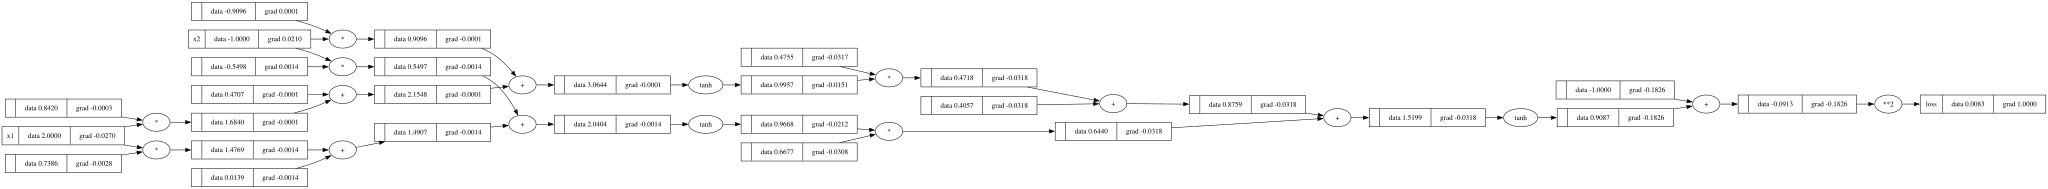

In [3]:
model = MLP(2, [2, 1])
x = [Value(2.0, label="x1"), Value(-1.0, label="x2")]
target = 1.0

for step in range(20):
    pred = model(x)
    loss = (pred - target) ** 2
    loss.label = "loss"

    model.zero_grad()
    loss.backward()

    for p in model.parameters():
        p.data += -0.05 * p.grad

    if step % 5 == 0 or step == 19:
        print(f"Step {step:2d} | Loss: {loss.data:.6f} | Pred: {pred.data:+.4f}")

# Visualize the final loss computation graph
draw_dot(loss)